# Tugas Individu Praktikum Deep Learning Minggu 5

Nama: Arya Pratama Hendri  
NIM: 2411533008

### Persiapan
Import, fungsi `create_sequences`, dan kelas `GRUModel` disalin dari kode modul minggu 5. Kelas `LSTMModel` disalin dari kode modul minggu 4 untuk Tugas 2.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

seq_length = 20

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i:i+seq_length])
        ys.append(data[i+seq_length])
    return np.array(xs), np.array(ys)

class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=1, num_layers=1):
        super(GRUModel, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=1, num_layers=1):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

### Tugas 1. Ubah fungsi data menjadi cosine dan ulangi pelatihan
`np.sin` diganti `np.cos`. Fungsi `latih` berisi training loop dari modul (50 epoch, Adam lr 0,01, MSELoss) ditambah pengukur waktu untuk kolom Waktu Training pada tabel Tugas 3.

In [2]:
# Data cosine
data_cos = np.cos(np.linspace(0, 100, 1000))
X_cos, y_cos = create_sequences(data_cos, seq_length)
X_cos = torch.FloatTensor(X_cos).unsqueeze(-1)
y_cos = torch.FloatTensor(y_cos).unsqueeze(-1)
print("Ukuran X_cos:", tuple(X_cos.shape), "| ukuran y_cos:", tuple(y_cos.shape))

# Training loop dari modul, ditambah pengukur waktu
def latih(model, X, y, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    losses = []
    mulai = time.time()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses, time.time() - mulai

Ukuran X_cos: (980, 20, 1) | ukuran y_cos: (980, 1)


Tiga konfigurasi GRU mengikuti tabel modul, dan dua LSTM berukuran sama sebagai pembanding untuk Tugas 2. `torch.manual_seed(42)` membuat bobot awal sama setiap kali dijalankan. Satu latihan singkat di awal hanya untuk pemanasan supaya model pertama tidak ikut menanggung waktu persiapan PyTorch.

GRU_1  hidden= 32 layers=1 | param:   3393 | loss akhir: 0.00012 | waktu: 1.09 s


GRU_2  hidden= 64 layers=1 | param:  12929 | loss akhir: 0.00010 | waktu: 1.82 s


GRU_3  hidden= 64 layers=2 | param:  37889 | loss akhir: 0.00075 | waktu: 4.23 s


LSTM_2 hidden= 64 layers=1 | param:  17217 | loss akhir: 0.00033 | waktu: 2.82 s


LSTM_3 hidden= 64 layers=2 | param:  50497 | loss akhir: 0.00123 | waktu: 5.89 s


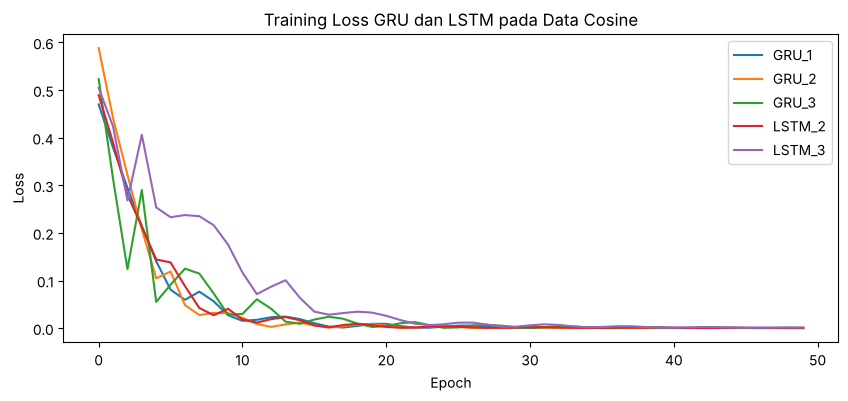

In [3]:
# Pemanasan (hasilnya dibuang)
latih(GRUModel(), X_cos, y_cos, epochs=5)

konfigurasi = [
    ("GRU_1", GRUModel, 32, 1),
    ("GRU_2", GRUModel, 64, 1),
    ("GRU_3", GRUModel, 64, 2),
    ("LSTM_2", LSTMModel, 64, 1),
    ("LSTM_3", LSTMModel, 64, 2),
]

hasil = {}
for nama, kelas, hidden, layers in konfigurasi:
    torch.manual_seed(42)
    m = kelas(hidden_size=hidden, num_layers=layers)
    jumlah_param = sum(p.numel() for p in m.parameters())
    losses_m, detik = latih(m, X_cos, y_cos)
    hasil[nama] = {"model": m, "hidden": hidden, "layers": layers,
                   "losses": losses_m, "detik": detik, "param": jumlah_param}
    print(f"{nama:6s} hidden={hidden:3d} layers={layers} | param: {jumlah_param:6d} | "
          f"loss akhir: {losses_m[-1]:.5f} | waktu: {detik:.2f} s")

# Plot loss seperti langkah 5 modul
plt.figure(figsize=(10,4))
for nama in hasil:
    plt.plot(hasil[nama]["losses"], label=nama)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss GRU dan LSTM pada Data Cosine')
plt.legend()
plt.show()

### Tugas 2. Bandingkan hasil prediksi dengan model LSTM minggu ke-4
Prediksi seperti langkah 6 modul, untuk GRU_2 dan LSTM_2 (hidden 64, satu layer).

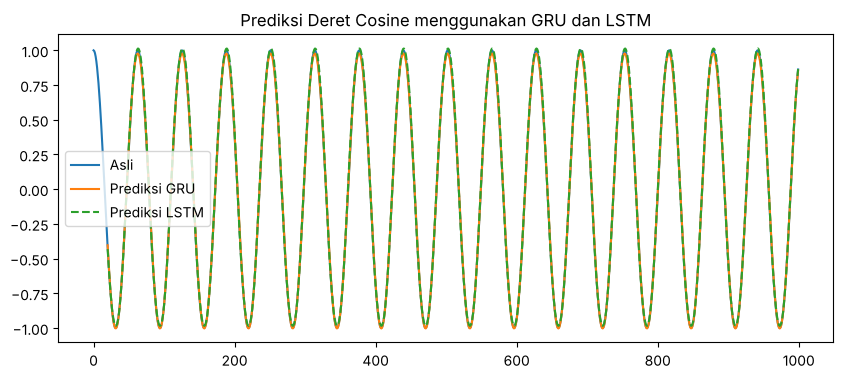

MSE GRU_2 : 0.00011
MSE LSTM_2: 0.00037


In [4]:
with torch.no_grad():
    preds_gru = hasil["GRU_2"]["model"](X_cos).numpy()
    preds_lstm = hasil["LSTM_2"]["model"](X_cos).numpy()

plt.figure(figsize=(10,4))
plt.plot(data_cos, label='Asli')
plt.plot(np.arange(seq_length, len(preds_gru)+seq_length), preds_gru, label='Prediksi GRU')
plt.plot(np.arange(seq_length, len(preds_lstm)+seq_length), preds_lstm, '--', label='Prediksi LSTM')
plt.legend()
plt.title('Prediksi Deret Cosine menggunakan GRU dan LSTM')
plt.show()

print(f"MSE GRU_2 : {np.mean((preds_gru - y_cos.numpy())**2):.5f}")
print(f"MSE LSTM_2: {np.mean((preds_lstm - y_cos.numpy())**2):.5f}")

### Tugas 3. Tabel hasil eksperimen
Kolom mengikuti tabel di modul.

In [5]:
tabel = pd.DataFrame([{
    "Model": nama,
    "Hidden Size": hasil[nama]["hidden"],
    "Num Layers": hasil[nama]["layers"],
    "Loss Akhir": round(hasil[nama]["losses"][-1], 5),
    "Waktu Training (s)": round(hasil[nama]["detik"], 2),
} for nama in ["GRU_1", "GRU_2", "GRU_3"]])
tabel

,Model,Hidden Size,Num Layers,Loss Akhir,Waktu Training (s)
0,GRU_1,32,1,0.00012,1.09
1,GRU_2,64,1,0.00010,1.82
2,GRU_3,64,2,0.00075,4.23


### Tugas 4. Kesimpulan efisiensi GRU dibanding LSTM

Loss akhir selalu sama karena memakai seed 42, sedangkan waktu training bergantung pada mesin yang menjalankan notebook.

Dengan ukuran yang sama, GRU memakai lebih sedikit parameter daripada LSTM (12.929 berbanding 17.217 pada hidden 64 satu layer), dilatih lebih cepat, dan loss akhirnya sekitar sepertiga loss LSTM (0,00010 berbanding 0,00033). Pada dua layer polanya sama: loss GRU_3 0,00075, sedangkan LSTM_3 0,00123. Prediksi GRU juga lebih dekat ke data asli (MSE 0,00011 berbanding 0,00037). Untuk prediksi deret waktu sederhana seperti gelombang cosine, GRU lebih efisien daripada LSTM. Layer kedua belum memberi manfaat dalam 50 epoch karena loss justru naik dan waktu training sekitar dua kali lipat.